# Homework 2

## Problem 1

The probability of rolling snake eyes is $\frac{1}{36}$. The probability of a sum to 7 is $\frac{1}{6}$ (we did this in class so I feel okay just citing it here, but just in case you add 1/5, 5/1, 2/4, 4/2, 3/3, 3/3 to get $\frac{6}{36}$); their ratio is 6, so a sum to seven is six times as likely as snake eyes. Next time I play craps in Vegas I will have to remember this.

## Problem 2

Numerically our convolution, for dice A and B, looks like $\displaystyle P_a(x) \ast P_b(x) = (P_a \ast P_b)(x) = \sum_{x = 1}^{6} P_a(x) * P_b(7 - x) = 6 * \frac{1}{36} = \frac{1}{6}$.

In code:

In [59]:
import scipy
import numpy as np
import pandas as pd
from fractions import Fraction as frac
from scipy import stats

onedice = np.array([1, 2, 3, 4, 5, 6])
twodice = np.arange(2, 13)
p_a = np.array([1/6, 1/6, 1/6, 1/6, 1/6, 1/6]) # our probabilities
p_b = p_a
odds = np.convolve(p_a, p_b, mode = 'full') # convolving our two distributions to get our sum probabilities
print(odds)
print(1/6)
print(np.sum(odds))

[0.02777778 0.05555556 0.08333333 0.11111111 0.13888889 0.16666667
 0.13888889 0.11111111 0.08333333 0.05555556 0.02777778]
0.16666666666666666
1.0


Our list above is the probability of summing to each number (2 to 12). At index 6 (pointing to a sum of 7) we see our $\frac{1}{6}$.

I added the sum just to check for normalization.

## Problem 3

Our mean is $\displaystyle \sum_{i = 1}^{11} x_i * \frac{1}{11}$ 

In [17]:
mean = np.sum(odds) * 1/len(odds)
print(mean)

0.09090909090909091


Which is $\frac{1}{11}$, which I suppose makes sense.

Our variance is $\displaystyle \sum_{i = 0}^{10} \frac{(x_i - \mu)^2}{N}$

In [28]:
variance = 0
for i in range(11):
    variance += (odds[i] - mean)**2 / 11
    
print(variance)
print(np.sqrt(variance))

0.0019768390980512197
0.04446165874156316


## Problem 4

Let's do it for 10 dice.

In [50]:
odds_ten = odds
tendice = np.arange (10, 61) / 6
for i in range(8):
    odds_ten = np.convolve(p_a, odds_ten, mode = 'full')
print(odds_ten)
print(len(odds_ten))
    

[1.65381717e-08 1.65381717e-07 9.09599443e-07 3.63839777e-06
 1.18247928e-05 3.31094197e-05 8.26081676e-05 1.87542867e-04
 3.92946959e-04 7.67701930e-04 1.40951530e-03 2.44665712e-03
 4.03407353e-03 6.34189270e-03 9.53533096e-03 1.37465945e-02
 1.90415547e-02 2.53867551e-02 3.26236936e-02 4.04573294e-02
 4.84643679e-02 5.61241048e-02 6.28704385e-02 6.81581055e-02
 7.15327194e-02 7.26928060e-02 7.15327194e-02 6.81581055e-02
 6.28704385e-02 5.61241048e-02 4.84643679e-02 4.04573294e-02
 3.26236936e-02 2.53867551e-02 1.90415547e-02 1.37465945e-02
 9.53533096e-03 6.34189270e-03 4.03407353e-03 2.44665712e-03
 1.40951530e-03 7.67701930e-04 3.92946959e-04 1.87542867e-04
 8.26081676e-05 3.31094197e-05 1.18247928e-05 3.63839777e-06
 9.09599443e-07 1.65381717e-07 1.65381717e-08]
51


Doing eight more convolutions gets us an array of probabilities with size 51, which makes sense as the values can be 1 to 6 inclusive (with a step size of 0.1).

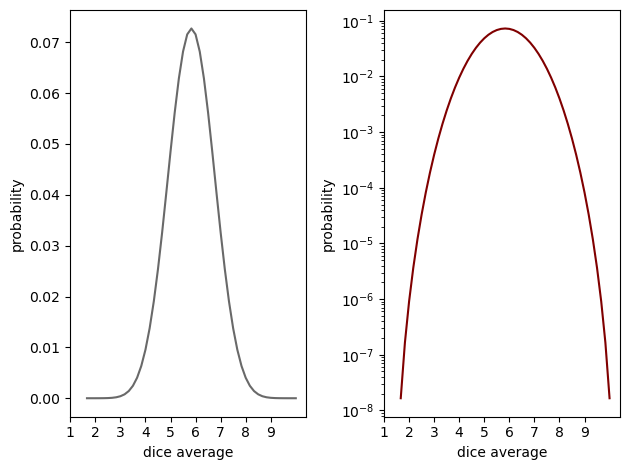

In [55]:
import matplotlib
import matplotlib.pyplot as plt

tenticks = np.arange(1, 10)

fig, ax = plt.subplots(1, 2)
ax[0].plot(tendice, odds_ten, color = 'dimgrey')
ax[0].set_xticks(tenticks)
ax[1].semilogy(tendice, odds_ten, color = 'maroon')
ax[1].set_xticks(tenticks)
plt.tick_params(labelsize = 10)
ax[0].set_xlabel('dice average')
ax[0].set_ylabel('probability')
ax[1].set_xlabel('dice average')
ax[1].set_ylabel('probability')
plt.tight_layout()
plt.show()

Looks pretty dang Gaussian, and the semilog plot looks pretty dang parabolic. Pardon my French. Looking over the Wikipedia page for the Central Limit Theorem, I believe we are seeing a clear case of averaging multiple distributions slowly morphing into a Gaussian distribution. We haven't actually covered much at all in class so I don't know what else to say, sorry.

## Problem 5

I'm a little confused as to what the question is asking, but I will do my best.

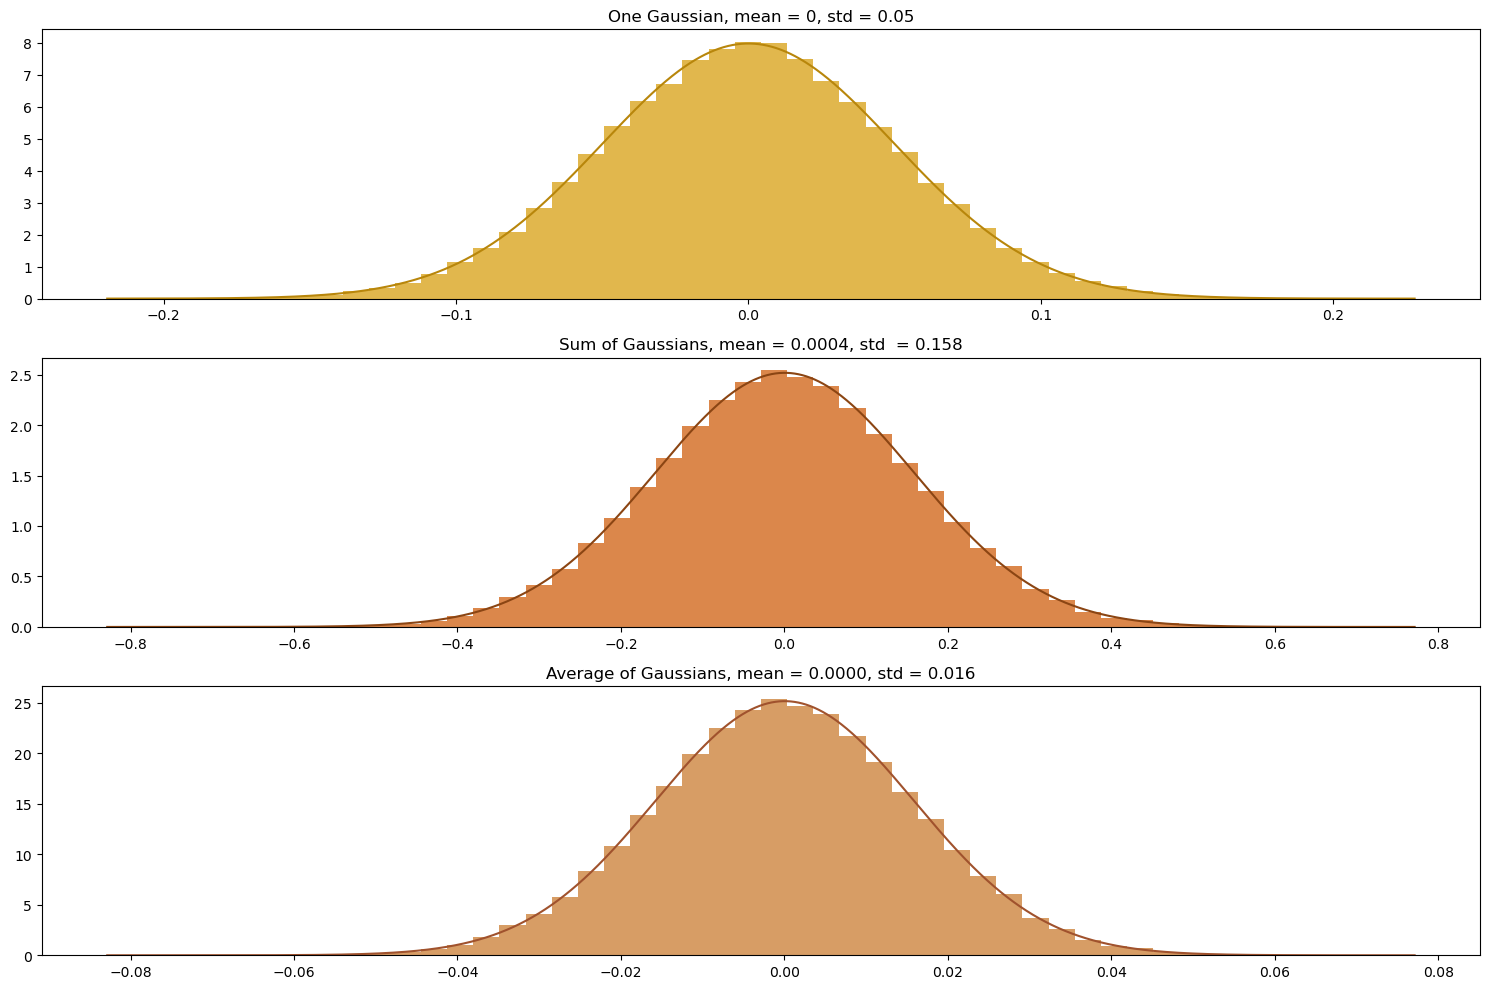

In [96]:
dist = np.zeros((10, 100000))
for i in range(10):
    dist[i] = stats.norm.rvs(loc = 0, scale = .05, size = 100000) # making ten Gaussian distributions

plt.rcParams["figure.figsize"] = (15,10)
x1 = np.linspace(dist[0].min(), dist[0].max(), 100000)
fig, ax = plt.subplots(3)
ax[0].hist(dist[0], 50, density = True, color = 'goldenrod', alpha = 0.8)
ax[0].plot(x1, stats.norm.pdf(x1, loc = 0, scale = .05), color = 'darkgoldenrod')
ax[0].set_title(f'One Gaussian, mean = 0, std = 0.05')
distsum = np.zeros(100000)
for i in range(10):
    distsum += dist[i] # our sum of Gaussians
x2 = np.linspace(distsum.min(), distsum.max(), 100000)
mu2, sig2 = stats.norm.fit(distsum)
ax[1].hist(distsum, 50, density = True, color = 'chocolate', alpha = 0.8)
ax[1].plot(x2, stats.norm.pdf(x2, loc = mu2, scale = sig2), color = 'saddlebrown')
ax[1].set_title(f'Sum of Gaussians, mean = {mu2:.4f}, std  = {sig2:.3f}')
distavg = distsum / 10 # our average of Gaussians
x3 = np.linspace(distavg.min(), distavg.max(), 100000)
mu3, sig3 = stats.norm.fit(distavg)
ax[2].hist(distavg, 50, density = True, color = 'peru', alpha = .8)
ax[2].plot(x3, stats.norm.pdf(x3, loc = mu3, scale = sig3), color = 'sienna')
ax[2].set_title(f'Average of Gaussians, mean = {mu3:.4f}, std = {sig3:.3f}')
plt.tight_layout()

plt.show()

I'm not sure if I am reaching the desired conclusion, but it seems to me that the mean shifts only minutely, while the standard deviation becomes much tighter as you average multiple runs. I agree that this is really cool! When integrating a signal over time, multiple runs of data collection will give you a tighter distribution. Again, we haven't really talked about error propogation yet in class so I don't know what to say about that.